In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)

Training data: (60000, 28, 28)
Testing data : (10000, 28, 28)


In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


In [4]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

C:\Users\TUF\anaconda3\envs\dogcat\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [5]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1,
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9310 - loss: 0.2254 - val_accuracy: 0.9733 - val_loss: 0.0939
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9710 - loss: 0.0945 - val_accuracy: 0.9718 - val_loss: 0.0957
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9782 - loss: 0.0678 - val_accuracy: 0.9777 - val_loss: 0.0817
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9831 - loss: 0.0528 - val_accuracy: 0.9802 - val_loss: 0.0810
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9872 - loss: 0.0403 - val_accuracy: 0.9745 - val_loss: 0.1011


In [8]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    # verbose=0
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 935us/step - accuracy: 0.9721 - loss: 0.0997

Test Loss: 0.09972745925188065
Test Accuracy: 0.972100019454956


In [9]:
predictions = model.predict(x_test)

# Get class with highest probability
y_pred = np.argmax(predictions, axis=1)

print("\nActual:", y_test[:10])
print("Predicted:", y_pred[:10])


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Actual: [7 2 1 0 4 1 4 9 5 9]
Predicted: [7 2 1 0 4 1 4 9 5 9]


In [10]:
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.96      0.97      1032
           3       0.98      0.97      0.98      1010
           4       0.97      0.96      0.97       982
           5       0.98      0.97      0.97       892
           6       0.99      0.95      0.97       958
           7       0.99      0.96      0.98      1028
           8       0.94      0.98      0.96       974
           9       0.95      0.97      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



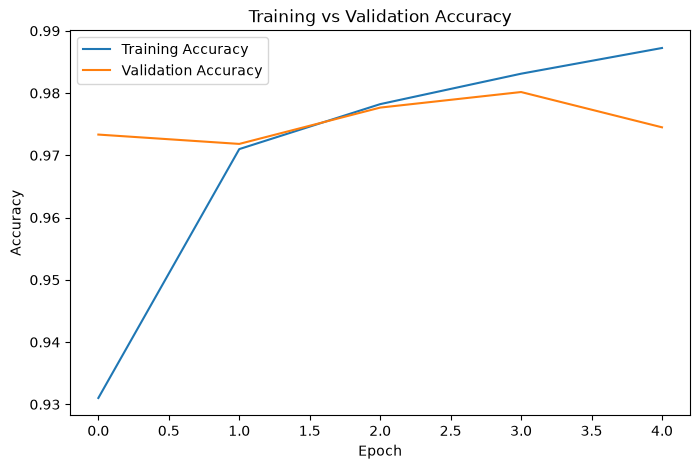

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.show()


Total incorrect predictions: 279


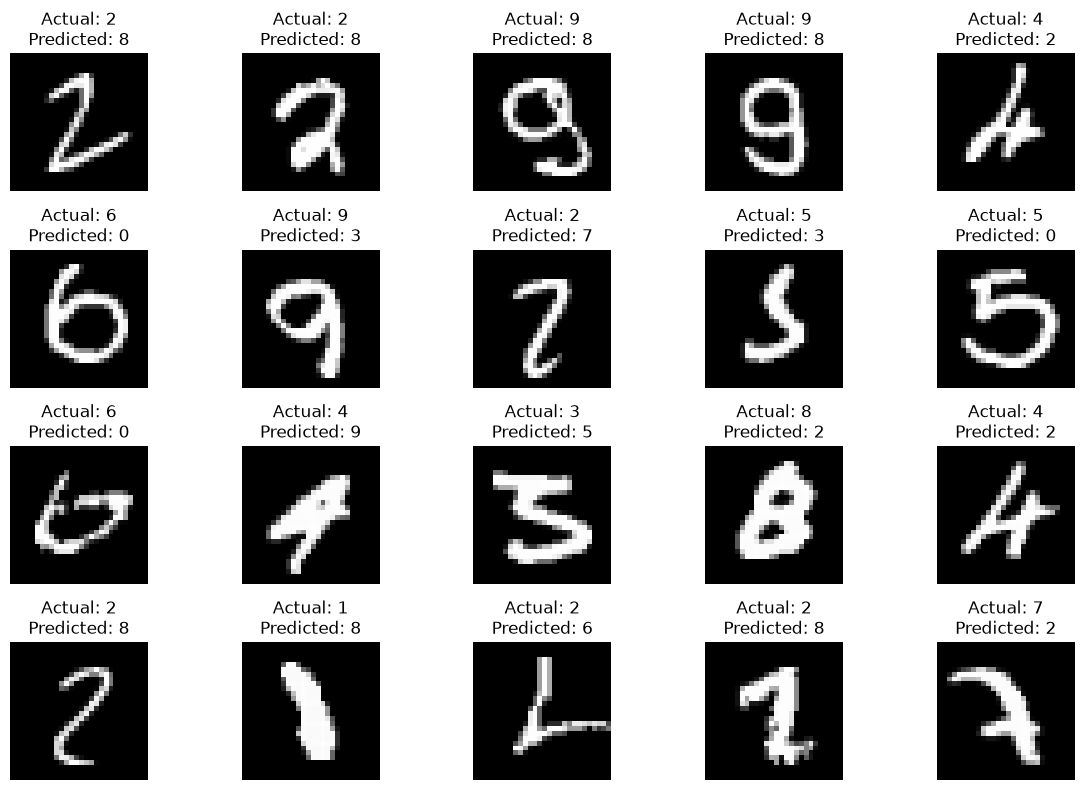

In [13]:
incorrect_indices = np.where(
    y_pred != y_test
)[0]

print("\nTotal incorrect predictions:",
      len(incorrect_indices))


plt.figure(figsize=(12, 8))

for i, index in enumerate(incorrect_indices[:20]):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        x_test[index],
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[index]}\n"
        f"Predicted: {y_pred[index]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
model.save("mnist_model.keras")

### For CNN

In [15]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [17]:
X_train_cnn = x_train.reshape(-1,28,28,1)
X_test_cnn = x_test.reshape(-1,28,28,1)

In [18]:
model = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')  
])

C:\Users\TUF\anaconda3\envs\dogcat\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [19]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [20]:
model.fit(
    X_train_cnn, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9269 - loss: 0.2365 - val_accuracy: 0.9810 - val_loss: 0.0618
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9753 - loss: 0.0810 - val_accuracy: 0.9860 - val_loss: 0.0449
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9802 - loss: 0.0617 - val_accuracy: 0.9897 - val_loss: 0.0365
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9842 - loss: 0.0513 - val_accuracy: 0.9912 - val_loss: 0.0319
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9860 - loss: 0.0440 - val_accuracy: 0.9895 - val_loss: 0.0323


In [21]:
test_loss, test_acc = model.evaluate(X_test_cnn, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")


Test Accuracy: 99.02%


In [25]:
model.save("mnist_model.keras")